### Exemplo Dataset Gerado - Classe Bivalorada

In [1]:
from sklearn.datasets import make_classification
nb_samples = 500
X, Y = make_classification(n_samples=nb_samples, n_features=3, n_informative=3, n_redundant=0, n_classes=3, n_clusters_per_class=1)
feature_names = ['A','B','C']
class_names=['C1', 'C2', 'C3']

#### Visualizar em 2D

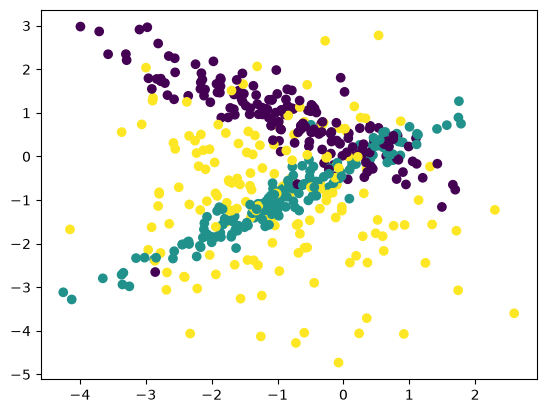

In [2]:
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=Y)
plt.show()

#### Visualizar em 3D

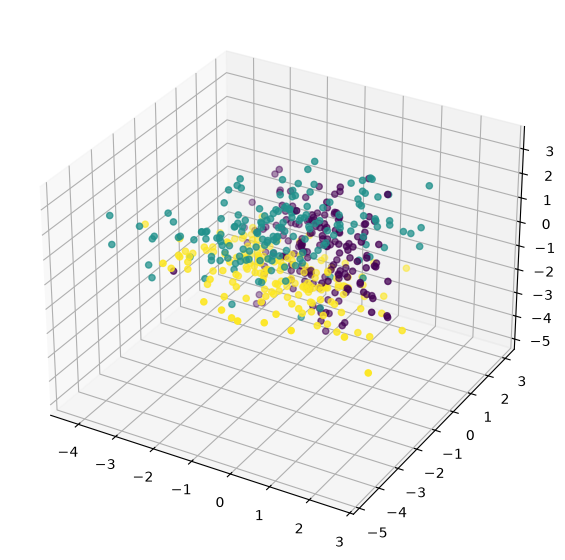

In [3]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=Y)
 
# show plot
plt.show()

#### Árvore usando Desigualdade de Gini

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score

#criterion="gini"
#criterion="entropy"
dt = DecisionTreeClassifier(criterion="gini")
print(cross_val_score(dt, X, Y, scoring='accuracy', cv=10).mean())


0.8140000000000001


#### Árvore usando Entropia Cruzada

In [5]:
dt = DecisionTreeClassifier(criterion="entropy")
print(cross_val_score(dt, X, Y, scoring='accuracy', cv=10).mean())


0.798


#### Plotando a Árvore

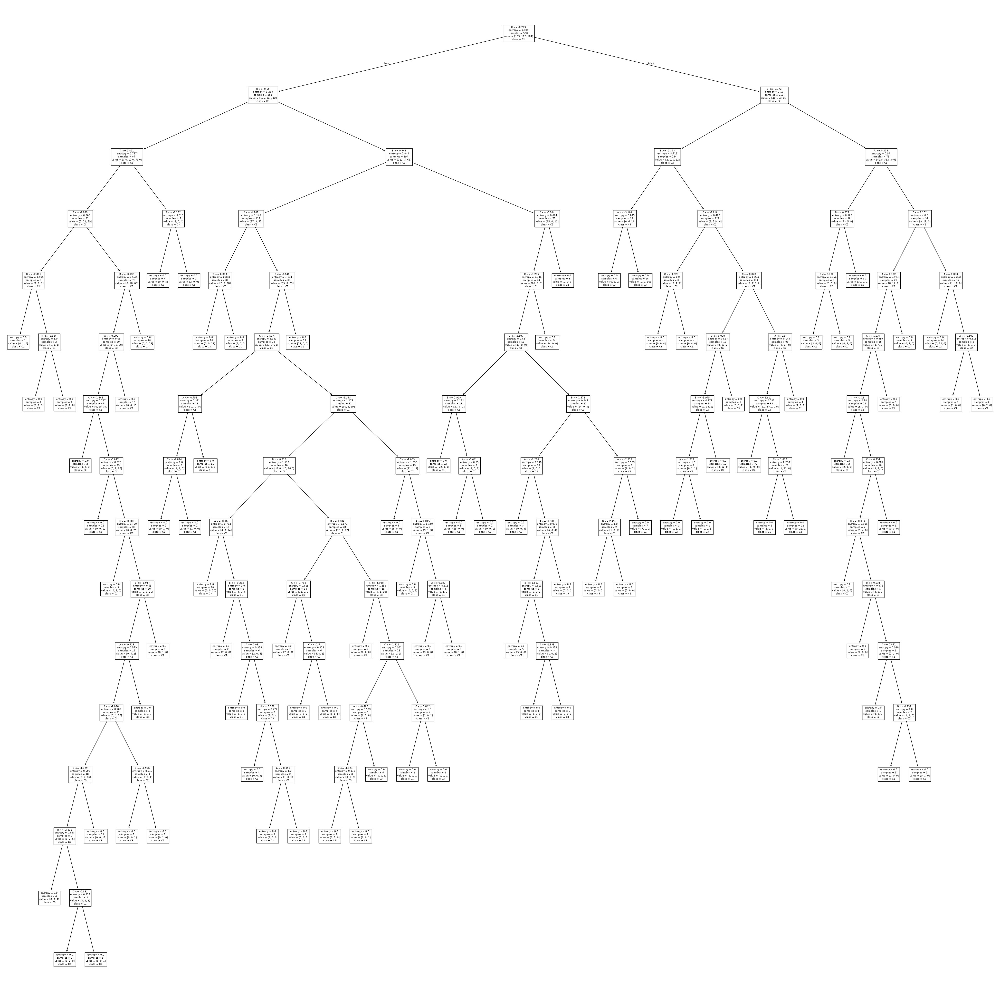

In [6]:
dt.fit(X,Y)
fig,ax = plt.subplots(figsize=(50,50))

plot_tree(dt, feature_names = feature_names, class_names = class_names)
plt.show()

### Exemplo Dataset Iris

In [7]:
from sklearn.datasets import load_iris
iris = load_iris()
X = iris.data
Y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

In [8]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

#### Visualizando Arbitrariamente em 2D

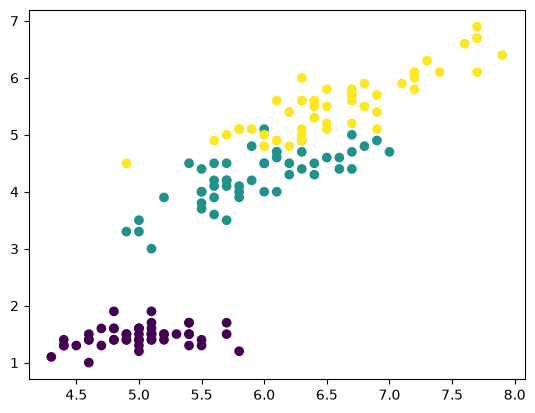

In [9]:
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 2], c=Y)
plt.show()

#### Visualizando Arbitrariamente em 3D

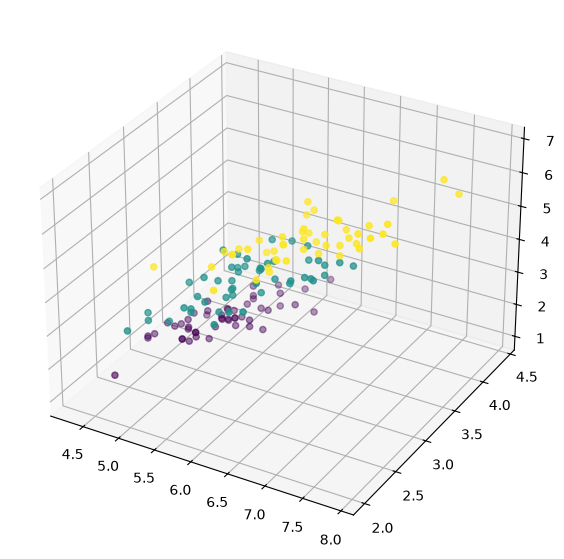

In [10]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=Y)
 
# show plot
plt.show()

#### Árvore usando Desigualdade de Gini

In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score

#criterion="gini"
#criterion="entropy"}
dt = DecisionTreeClassifier(criterion="gini")
print(cross_val_score(dt, X, Y, scoring='accuracy', cv=10).mean())

0.96


#### Árvore usando Entropia Cruzada

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score

#criterion="gini"
#criterion="entropy"
dt = DecisionTreeClassifier(criterion="entropy", min_samples_split=50)
print(cross_val_score(dt, X, Y, scoring='accuracy', cv=10).mean())

0.9466666666666667


#### Plotando a Árvore

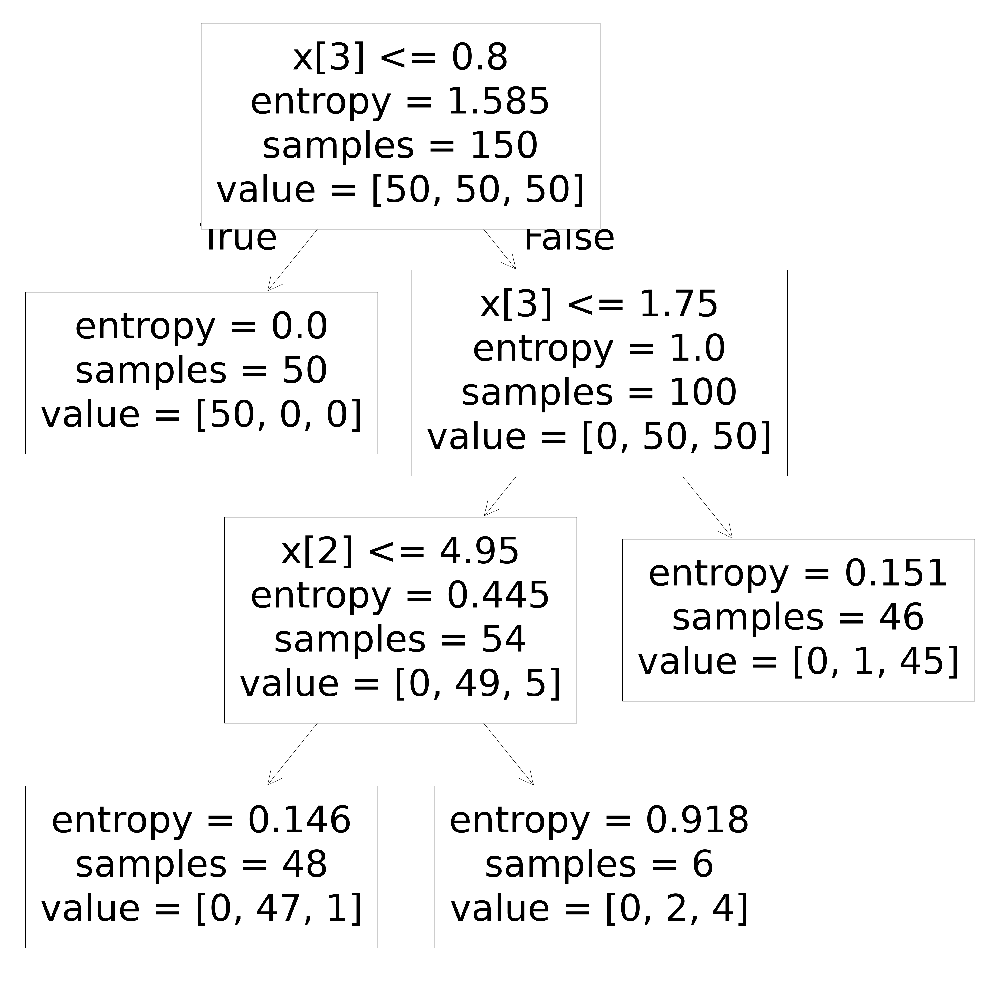

In [13]:
dt.fit(X,Y)
fig,ax = plt.subplots(figsize=(50,50))

plot_tree(dt)

plt.show()

#### Plotando a Árvore com Graphviz

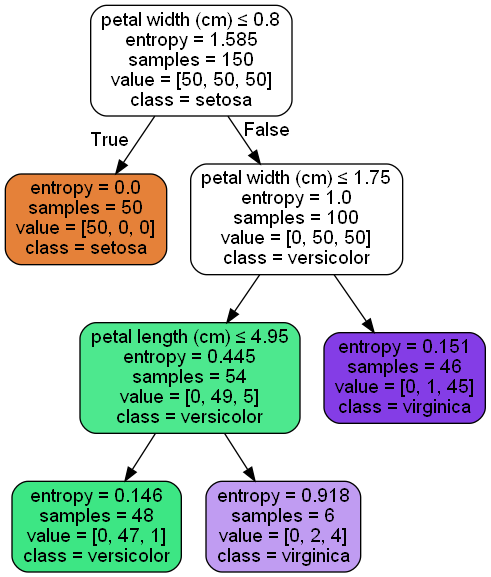

In [14]:
from sklearn.tree import export_graphviz

dt.fit(X, Y)
with open('tree.dot', 'w') as df:
    df = export_graphviz(dt, out_file=df, 
                         feature_names=feature_names, 
                         class_names=class_names,
                         filled=True, rounded=True,  
                         special_characters=True)

# Instalar Graphviz (incluindo no path)
import os    
os.system('dot -Tpng tree.dot -o tree.png')

# Exibir imagem|
from IPython.display import Image
Image(filename='tree.png') 

### Exportando Regras de uma árvore

In [15]:
from sklearn import tree
text_representation = tree.export_text(dt, feature_names=feature_names)
print(text_representation)

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2



### Geração de Código em Python c/ Regras aprendidas

In [17]:
import re
import numpy as np
from sklearn.tree import _tree

def clean(varStr):
    return re.sub(r'\W|^(?=\d)', '_', varStr)

def tree_to_code(tree, feature_names, class_names):
    tree_ = tree.tree_

    feature_name = [clean(f) for f in feature_names]

    print("def predict({}):".format(", ".join(feature_name)))

    def recurse(node, depth):
        indent = "    " * depth

        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[tree_.feature[node]]
            threshold = tree_.threshold[node]

            print(f"{indent}if {name} <= {threshold:.6f}:")
            recurse(tree_.children_left[node], depth + 1)

            print(f"{indent}else:")
            recurse(tree_.children_right[node], depth + 1)

        else:
            sel_class = np.argmax(tree_.value[node][0])
            c_name = repr(str(class_names[sel_class]))

            print(f"{indent}return {c_name}")

    recurse(0, 1)

In [20]:
#dt = DecisionTreeClassifier(criterion="entropy", min_samples_split=50)
dt.fit(X,Y)
tree_to_code(tree=dt, feature_names=feature_names, class_names=class_names)
recurse(dt,0, 1)

def predict(sepal_length__cm_, sepal_width__cm_, petal_length__cm_, petal_width__cm_):
    if petal_width__cm_ <= 0.800000:
        return 'setosa'
    else:
        if petal_width__cm_ <= 1.750000:
            if petal_length__cm_ <= 4.950000:
                return 'versicolor'
            else:
                return 'virginica'
        else:
            return 'virginica'
    if petal_width__cm_ <= 0.8:
        return 'setosa'
    else:  # if petal_width__cm_ > 0.8
        if petal_width__cm_ <= 1.75:
            if petal_length__cm_ <= 4.95:
                return 'versicolor'
            else:  # if petal_length__cm_ > 4.95
                return 'virginica'
        else:  # if petal_width__cm_ > 1.75
            return 'virginica'


#### Vamos testar o código gerado?

In [21]:
def predict(sepal_length__cm_, sepal_width__cm_, petal_length__cm_, petal_width__cm_):
    if petal_width__cm_ <= 0.800000:
        return 'setosa'
    else:
        if petal_width__cm_ <= 1.750000:
            if petal_length__cm_ <= 4.950000:
                return 'versicolor'
            else:
                return 'virginica'
        else:
            return 'virginica'
    if petal_width__cm_ <= 0.8:
        return 'setosa'
    else:  # if petal_width__cm_ > 0.8
        if petal_width__cm_ <= 1.75:
            if petal_length__cm_ <= 4.95:
                return 'versicolor'
            else:  # if petal_length__cm_ > 4.95
                return 'virginica'
        else:  # if petal_width__cm_ > 1.75
            return 'virginica'


#### Resultado da função gerada

In [22]:
c = 0
for i in range(len(iris.data)):
    predicted_class = predict(X[i][0],X[i][1],X[i][2],X[i][3])
    print(i,  predicted_class, class_names[Y[i]], predicted_class== class_names[Y[i]])
    if predicted_class== class_names[Y[i]] : c = c+1
print(c/len(iris.data))

0 setosa setosa True
1 setosa setosa True
2 setosa setosa True
3 setosa setosa True
4 setosa setosa True
5 setosa setosa True
6 setosa setosa True
7 setosa setosa True
8 setosa setosa True
9 setosa setosa True
10 setosa setosa True
11 setosa setosa True
12 setosa setosa True
13 setosa setosa True
14 setosa setosa True
15 setosa setosa True
16 setosa setosa True
17 setosa setosa True
18 setosa setosa True
19 setosa setosa True
20 setosa setosa True
21 setosa setosa True
22 setosa setosa True
23 setosa setosa True
24 setosa setosa True
25 setosa setosa True
26 setosa setosa True
27 setosa setosa True
28 setosa setosa True
29 setosa setosa True
30 setosa setosa True
31 setosa setosa True
32 setosa setosa True
33 setosa setosa True
34 setosa setosa True
35 setosa setosa True
36 setosa setosa True
37 setosa setosa True
38 setosa setosa True
39 setosa setosa True
40 setosa setosa True
41 setosa setosa True
42 setosa setosa True
43 setosa setosa True
44 setosa setosa True
45 setosa setosa Tru

### Análise dos Atributos

In [23]:
import numpy as np

dt = DecisionTreeClassifier(criterion="gini")
dt.fit(X,Y)

print(dt.feature_importances_)
print(np.argsort(dt.feature_importances_))
print(feature_names)


[0.02666667 0.         0.05072262 0.92261071]
[1 0 2 3]
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [31]:
#from sklearn.datasets import load_iris
#from sklearn.tree import DecisionTreeClassifier
import pandas as pd

#iris = load_iris()

#dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt = DecisionTreeClassifier(random_state=42)

dt.fit(iris.data, iris.target)

importance = pd.Series(dt.feature_importances_,
    index=iris.feature_names)

print(importance.sort_values(ascending=False))


petal length (cm)    0.564056
petal width (cm)     0.422611
sepal length (cm)    0.013333
sepal width (cm)     0.000000
dtype: float64


#### Verifica Importância dos Atributos

In [37]:
dt.feature_importances_

array([0.01333333, 0.        , 0.56405596, 0.42261071])

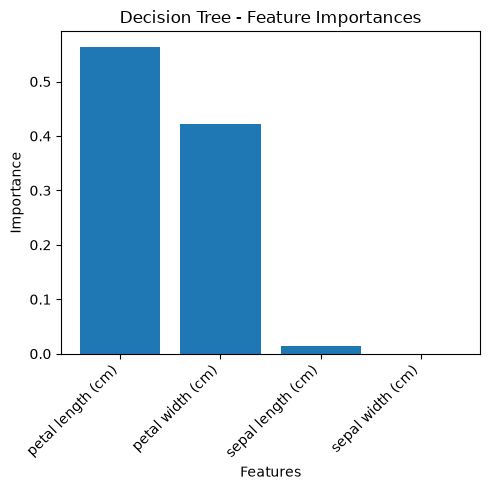

In [45]:
import numpy as np
import matplotlib.pyplot as plt

importances = dt.feature_importances_
indices = np.argsort(importances)[::-1]

names = np.array(feature_names)[indices]
values = importances[indices]

fig, ax = plt.subplots(figsize=(5, 5))


ax.bar(names, values)

ax.set_xlabel("Features")
ax.set_ylabel("Importance")
ax.set_title("Decision Tree - Feature Importances")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [46]:
feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

#### Testando parâmetros

In [47]:
print(cross_val_score(DecisionTreeClassifier(), X, Y, scoring='accuracy', cv=10).mean())

print(cross_val_score(DecisionTreeClassifier(max_features=None), X, Y, scoring='accuracy', cv=10).mean())

print(cross_val_score(DecisionTreeClassifier(min_samples_split=3), X, Y, scoring='accuracy', cv=10).mean())


0.96
0.9533333333333334
0.9533333333333334


#### Comparando com Regressão Logística

In [48]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
print(cross_val_score(lr, X, Y, scoring='accuracy', cv=10).mean())

0.9733333333333334


## Autotune - Encontrar melhores Parâmetros

In [49]:
import multiprocessing 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.datasets import load_digits 
 
param_grid = [
 { 
   'criterion': ['gini', 'entropy'],
   'max_features': ['sqrt', 'log2', None],
   'min_samples_split': [ 2, 10, 25, 50, 100 ],
   'max_depth': [2, 3, 4, 5, None]
 }
]

gs = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=param_grid,
                  scoring='accuracy', cv=10, n_jobs=multiprocessing.cpu_count())

gs.fit(X, Y)

print(gs.best_estimator_)
print(gs.best_estimator_.get_params())  

print(gs.best_score_)

DecisionTreeClassifier(max_depth=4, max_features='log2', min_samples_split=10)
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'max_features': 'log2', 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': None, 'splitter': 'best'}
0.9666666666666666


In [50]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=1000)

In [51]:
gs.best_estimator_.fit(X_train, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",'log2'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [52]:
dt = DecisionTreeClassifier(criterion="entropy")
print(cross_val_score(dt, X_train, Y_train, scoring='accuracy', cv=10).mean())

0.9636363636363636


In [53]:
#y_score = gs.best_estimator_.predict(X_test)
cross_val_score(gs.best_estimator_, X_test, Y_test, scoring='accuracy', cv=10).mean()

np.float64(0.905)

### ROC - Receiver Operating Characteristic

### Multiclass

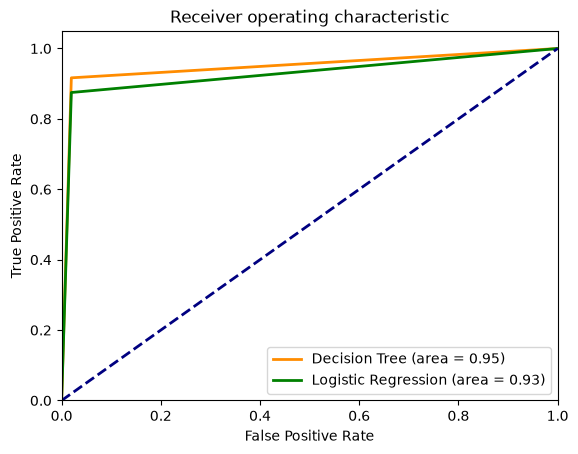

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import cycle

from sklearn import svm, datasets
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score


def calculate_roc(classifier, X_train, y_train, X_test, y_test):
    # Learn to predict each class against the other
    
    c = classifier.fit(X_train, y_train)
    y_score = c.predict(X_test)

    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    return fpr, tpr, roc_auc

# Binarize the output
y = label_binarize(Y, classes=list(set(Y)))
n_classes = y.shape[1]


# shuffle and split training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)


classifier = dt#gs.best_estimator_

fpr, tpr, roc_auc = calculate_roc(classifier, X_train, y_train, X_test, y_test)

plt.figure()
lw = 2
plt.plot(
    fpr[2],
    tpr[2],
    color="darkorange",
    lw=lw,
    label="Decision Tree (area = %0.2f)" % roc_auc[2],
)

classifier = OneVsRestClassifier(
    LogisticRegression(max_iter=1000)
)

fpr, tpr, roc_auc = calculate_roc(classifier, X_train, y_train, X_test, y_test)

plt.plot(
    fpr[2],
    tpr[2],
    color="green",
    lw=lw,
    label="Logistic Regression (area = %0.2f)" % roc_auc[2],
)
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

### Exempo MNIST

In [55]:
import multiprocessing 
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.datasets import load_digits 
 
digits = load_digits() 
 
param_grid = [
 { 
   'criterion': ['gini', 'entropy'],
   'max_features': ['sqrt', 'log2', None],
   'min_samples_split': [ 2, 10, 25, 100, 200 ],
   'max_depth': [5, 10, 15, None]
 }
]

gs = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=param_grid,
                  scoring='accuracy', cv=10, n_jobs=multiprocessing.cpu_count())

gs.fit(digits.data, digits.target)

print(gs.best_estimator_)
print(gs.best_estimator_.get_params())  

print(gs.best_score_)


DecisionTreeClassifier()
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': None, 'splitter': 'best'}
0.8302482929857232


In [56]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

#### Plotar a Árvore (impossível de ver)

In [57]:

fig,ax = plt.subplots(figsize=(150,150))

plot_tree(gs.best_estimator_)

plt.show()

### Calcular ROC p/ MNIST

In [58]:
# Binarize the output
y = label_binarize(digits.target, classes=list(set(digits.target)))
n_classes = y.shape[1]

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import cycle

from sklearn import svm, datasets
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

# shuffle and split training and test sets
X_train, X_test, y_train, y_test = train_test_split(digits.data, y, test_size=0.5, random_state=0)

# Learn to predict each class against the other
classifier = gs.best_estimator_

y_score = classifier.fit(X_train, y_train).predict(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

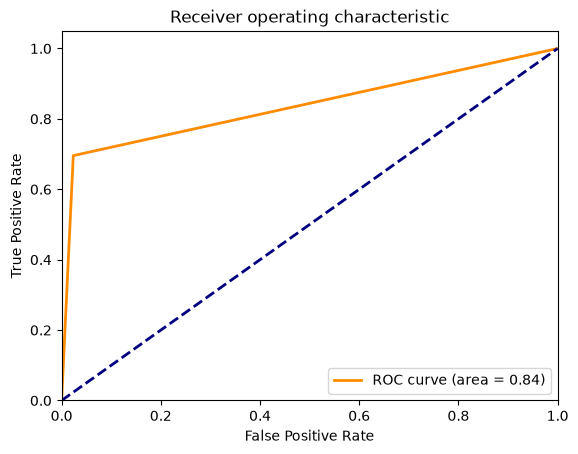

In [60]:
plt.figure()
lw = 2
plt.plot(
    fpr[2],
    tpr[2],
    color="darkorange",
    lw=lw,
    label="ROC curve (area = %0.2f)" % roc_auc[2],
)
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

### Matriz de Confusão

In [61]:
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.3, random_state=0)

y_score = classifier.fit(X_train, y_train).predict(X_test)

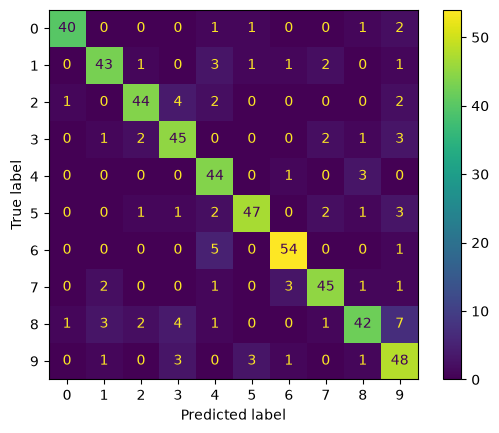

In [62]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_score)

cm_display = ConfusionMatrixDisplay(cm).plot()

### Análise ROC - Uma classe

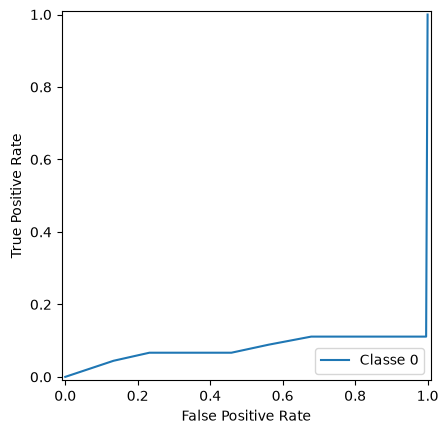

In [64]:
from sklearn.metrics import roc_curve
from sklearn.metrics import RocCurveDisplay

pos_class = classifier.classes_[0]

fpr, tpr, _ = roc_curve(y_test, y_score, pos_label=pos_class)
roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr,
                              name=f"Classe {pos_class}")


roc_display.plot()

In [65]:
classifier.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

### Análise Precision x Recall - Uma Classe

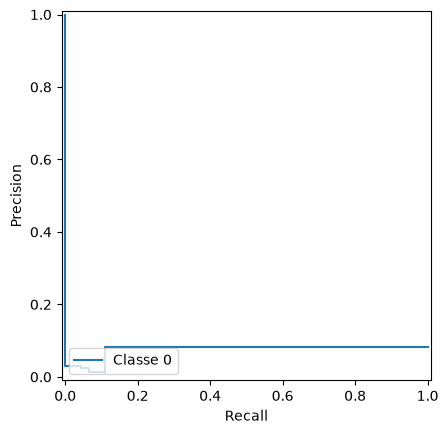

In [71]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import PrecisionRecallDisplay

pos_class = classifier.classes_[0]

prec, recall, _ = precision_recall_curve(y_test, y_score, pos_label=pos_class)
pr_display = PrecisionRecallDisplay(precision=prec, recall=recall,  name=f"Classe {pos_class}").plot()

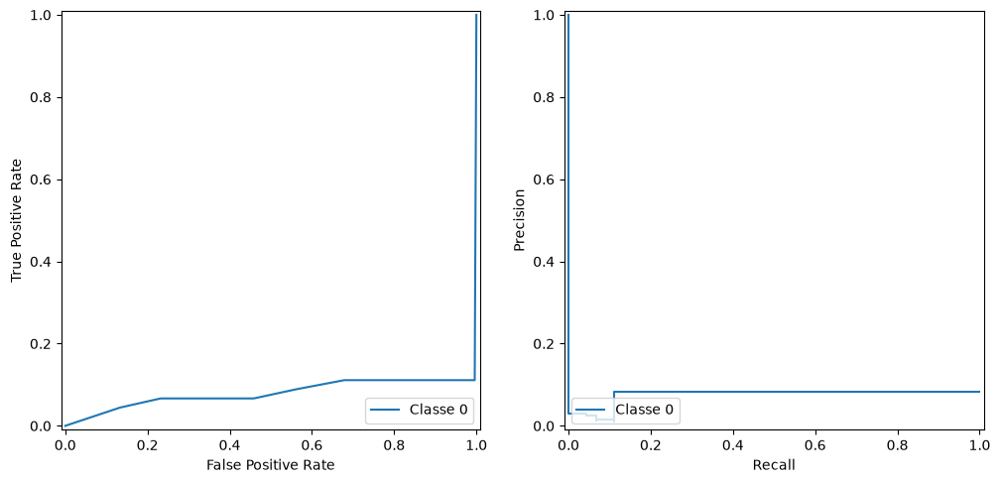

In [72]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

roc_display.plot(ax=ax1)
pr_display.plot(ax=ax2)
plt.show()

### Análise Multi classe

In [73]:
classifier.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

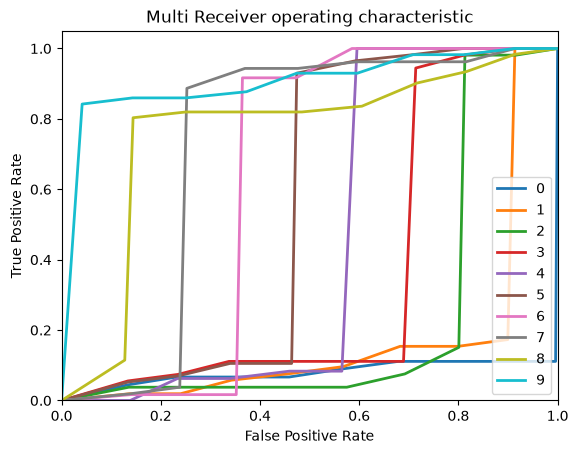

In [74]:
plt.figure()
lw = 2

for i in classifier.classes_:
    fpr, tpr, _ = roc_curve(y_test, y_score, pos_label=i)
    plt.plot(fpr, tpr,
    lw=lw,
    label=i,
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

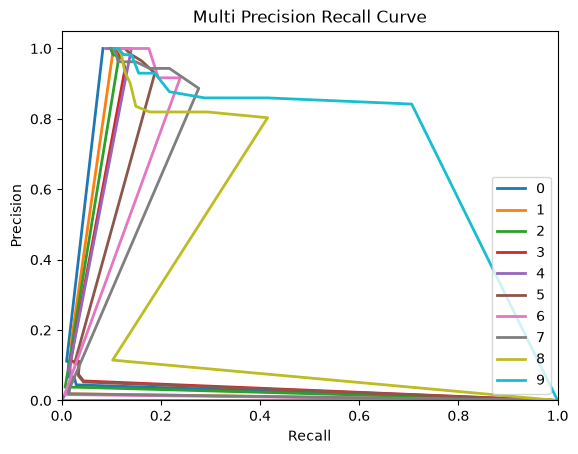

In [75]:
plt.figure()
lw = 2

for i in classifier.classes_:
    prec, recall, _ = precision_recall_curve(y_test, y_score, pos_label=i)
    plt.plot(prec, recall,
    lw=lw,
    label=i,
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Multi Precision Recall Curve")
plt.legend(loc="lower right")
plt.show()

## Regressão

In [76]:
import pandas as pd

file_path = 'dataset/Concrete_Data.xls'

df = pd.read_excel(file_path, header=0)

X = df.iloc[:, 0:8].values
Y = df.iloc[:, 8].values


In [77]:
len(X)

1030

In [78]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score

print(cross_val_score(DecisionTreeRegressor(criterion='squared_error', max_depth=3, random_state=1000), X, Y, cv=10).mean())

0.22250779437186763


In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=200, random_state=1000)

dtr = DecisionTreeRegressor(criterion='squared_error', max_depth=11, random_state=1000)
dtr.fit(X_train, Y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1000
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with




In [80]:
from sklearn.tree import export_graphviz

graphviz_path = 'Concrete_Data.dot'
feature_names=['Cement','Blast furnace slag', 'Fly ash','Water',
                               'Superplasticizer','Coarse Aggregate','Fine Aggregate','Age']


export_graphviz(dtr, out_file=graphviz_path, 
                     feature_names=feature_names, 
                     filled=True, rounded=True,  
                     special_characters=True
               )
                         


# Instalar Graphviz (incluindo no path)
import os    
os.system('dot -Tpng Concrete_Data.dot -o Concrete_Data.png')

# Exibir imagem|
from IPython.display import Image
Image(filename='Concrete_Data.png') 

In [81]:
print(dtr.score(X_train, Y_train))
print(dtr.score(X_test, Y_test))


0.9880681390461817
0.8088323415565082


#### Diabetes dataset

In [82]:
from sklearn.datasets import load_diabetes 
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
 
ds = load_diabetes() 
X = ds.data
Y = ds.target
print(cross_val_score(DecisionTreeRegressor(criterion='squared_error', max_depth=11, random_state=1000), X, Y, cv=20))


[-1.53811349  0.23995343 -0.43049987 -0.06875785 -0.05486208 -0.52120076
 -0.27371231 -0.01573328 -2.29486961 -0.10246452  0.3141986   0.48217967
 -0.17493603 -0.08484088 -0.63717965 -0.71204321 -0.32555091 -0.59444599
  0.21290732  0.09182258]


In [83]:
print(ds.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [84]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=200, random_state=1000)

dtr = DecisionTreeRegressor(criterion='squared_error', max_depth=None, random_state=1000)
dtr.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1000
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree wi

In [85]:
from sklearn.tree import export_graphviz

graphviz_path = 'diabetes.dot'

export_graphviz(dtr, out_file=graphviz_path, 
                     feature_names=ds.feature_names, 
                     filled=True, rounded=True,  
                     special_characters=True
               )
                         


# Instalar Graphviz (incluindo no path)
import os    
os.system('dot -Tpng diabetes.dot -o diabetes.png')

# Exibir imagem|
from IPython.display import Image
Image(filename='diabetes.png') 

In [86]:
print(dtr.score(X_train, Y_train))

print(dtr.score(X_test, Y_test))


1.0
-0.01602569748778282


#### California Housing dataset

In [87]:
from sklearn.datasets import fetch_california_housing 
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
 
ds = fetch_california_housing() 
X = ds.data
Y = ds.target
print(cross_val_score(DecisionTreeRegressor(criterion='squared_error', max_depth=11, random_state=1000), X, Y, cv=20))


[-0.54798778  0.54872114 -4.75932317  0.64979204  0.21782617  0.66569477
  0.56685357  0.27287021  0.59943959  0.53834902  0.54418824  0.48670526
  0.23845955  0.16727312  0.42310279  0.26324134  0.37339393  0.43447517
  0.27601755  0.58687363]


In [88]:
print(ds.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [89]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=200, random_state=1000)

dtr = DecisionTreeRegressor(criterion='squared_error', max_depth=11, random_state=1000)
dtr.fit(X_train, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1000
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [90]:
from sklearn.tree import export_graphviz

graphviz_path = 'california_housing.dot'

export_graphviz(dtr, out_file=graphviz_path, 
                feature_names=ds.feature_names,
               filled=True, rounded=True,  
                     special_characters=True)




In [91]:
import os    
os.system('dot -Tpng california_housing.dot -o california_housing.png')

# Exibir imagem
from IPython.display import Image
Image(filename='california_housing.png') 

In [92]:
print(dtr.score(X_train, Y_train))

print(dtr.score(X_test, Y_test))


0.8592867420683727
0.7161536587372761


#### Dado Real x Predito

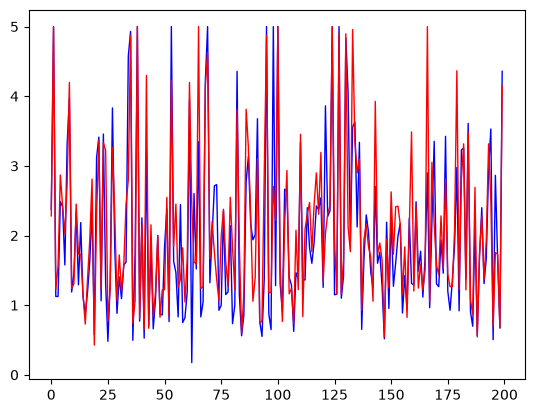

In [93]:
import matplotlib.pyplot as plt

Y_pred = dtr.predict(X_test)

plt.plot(Y_test, color="blue", linewidth=1, label="Target")
plt.plot(Y_pred, color="red", linewidth=1, label="Pred")
plt.show()

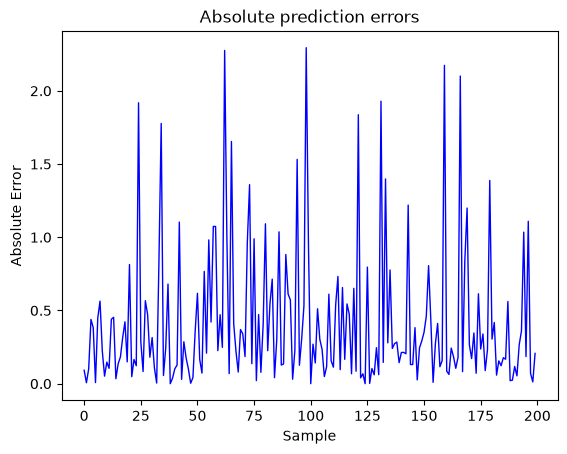

In [94]:
import matplotlib.pyplot as plt

AE = abs(Y_test-Y_pred)

plt.plot(AE, color="blue", linewidth=1)
plt.title("Absolute prediction errors")
plt.xlabel("Sample")
plt.ylabel("Absolute Error")
plt.show()

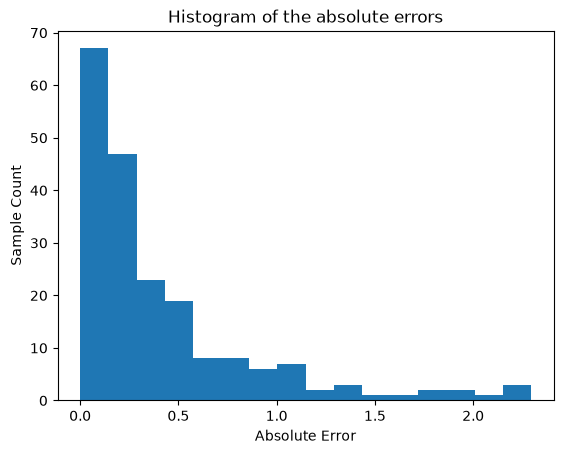

In [95]:
import matplotlib.pyplot as plt
plt.hist(AE, bins='auto')
plt.xlabel("Absolute Error")
plt.ylabel("Sample Count")
plt.title("Histogram of the absolute errors")
plt.show()